# Experiment Results: Hyperparameters, Ablation, CV, and Segmentation

This notebook visualizes results from `reports/experiment_log.csv`, which is
populated by running:

```bash
python -m src.pipeline --dataset rossmann
python -m src.experiments.hyperparam_search --dataset rossmann
python -m src.experiments.ablation_study --dataset rossmann
python -m src.experiments.rolling_cv --dataset rossmann
python -m src.experiments.segment_analysis --dataset rossmann
```

Run those first (see README) so the log has data. Each script also saves its
own chart directly to `reports/figures/` when run -- this notebook reloads
those results and adds one additional cross-experiment view at the end.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from src.experiment_log import load_experiment_log
from src.experiments.plots import plot_experiment_log_overview

log_df = load_experiment_log(Path('../reports/experiment_log.csv'))
print(f'{len(log_df)} experiment runs logged so far.')
log_df[['timestamp', 'run_type', 'dataset', 'tag', 'hidden_size', 'input_window', 'pinball_loss', 'empirical_coverage']]

13 experiment runs logged so far.


,timestamp,run_type,dataset,tag,hidden_size,input_window,pinball_loss,empirical_coverage
0,2026-07-25T03:28:42+00:00,main_pipeline,rossmann,full_run,64,28,6.2077,0.2286
1,2026-07-25T03:28:52+00:00,hyperparam_search,rossmann,hs32_iw14,32,14,13.7277,0.0807
2,2026-07-25T03:28:56+00:00,hyperparam_search,rossmann,hs32_iw28,32,28,13.6445,0.0198
3,2026-07-25T03:29:01+00:00,hyperparam_search,rossmann,hs64_iw14,64,14,11.4682,0.0807
4,2026-07-25T03:29:10+00:00,hyperparam_search,rossmann,hs64_iw28,64,28,11.4733,0.0594
5,2026-07-25T03:29:25+00:00,hyperparam_search,rossmann,hs128_iw14,128,14,6.5057,0.2313
6,2026-07-25T03:29:54+00:00,hyperparam_search,rossmann,hs128_iw28,128,28,6.9538,0.1861
7,2026-07-25T03:30:04+00:00,ablation_study,rossmann,target_only,64,28,6.1475,0.2789
8,2026-07-25T03:30:16+00:00,ablation_study,rossmann,with_extra_features,64,28,10.0303,0.0566
9,2026-07-25T03:30:29+00:00,rolling_cv,rossmann,fold_1,64,28,12.9511,0.0612


## 1. Hyperparameter Search Results

Loaded from the log and re-displayed here; the heatmap PNG was already saved
by `hyperparam_search.py` to `reports/figures/hyperparam_search_heatmap.png`
when the script ran -- shown inline below.

,tag,hidden_size,input_window,pinball_loss,mae,empirical_coverage
5,hs128_iw14,128,14,6.5057,14.8419,0.2313
6,hs128_iw28,128,28,6.9538,15.4208,0.1861
3,hs64_iw14,64,14,11.4682,23.2759,0.0807
4,hs64_iw28,64,28,11.4733,23.3273,0.0594
2,hs32_iw28,32,28,13.6445,27.6302,0.0198
1,hs32_iw14,32,14,13.7277,27.7406,0.0807


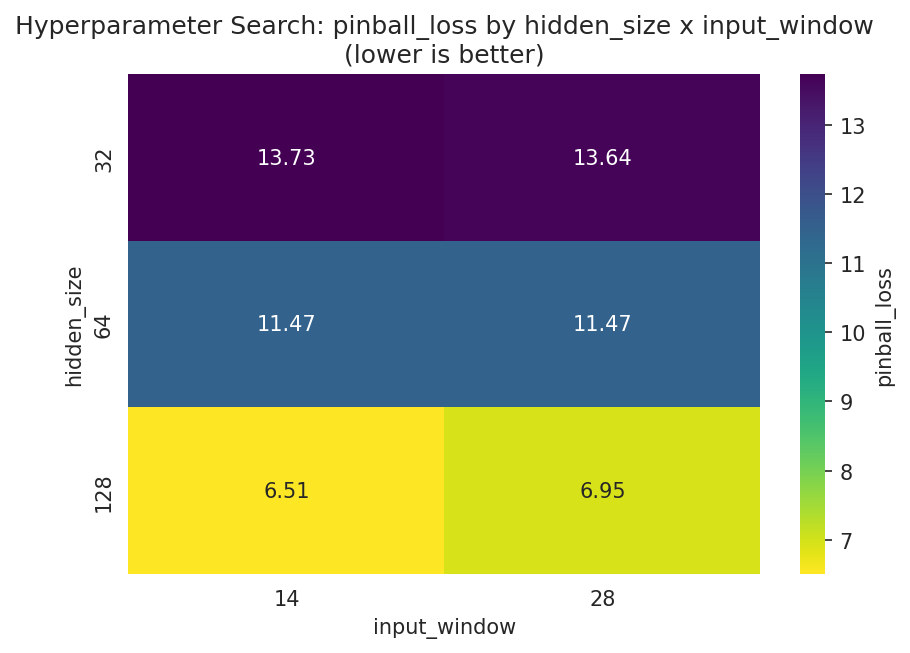

In [2]:
hp_df = log_df[log_df['run_type'] == 'hyperparam_search'].sort_values('pinball_loss')
display(hp_df[['tag', 'hidden_size', 'input_window', 'pinball_loss', 'mae', 'empirical_coverage']])

from PIL import Image
img_path = Path('../reports/figures/hyperparam_search_heatmap.png')
if img_path.exists():
    display(Image.open(img_path))
else:
    print('Run `python -m src.experiments.hyperparam_search` first to generate this chart.')

## 2. Feature Ablation Results

,tag,n_features,pinball_loss,mae,empirical_coverage
7,target_only,1,6.1475,14.3348,0.2789
8,with_extra_features,6,10.0303,20.5885,0.0566


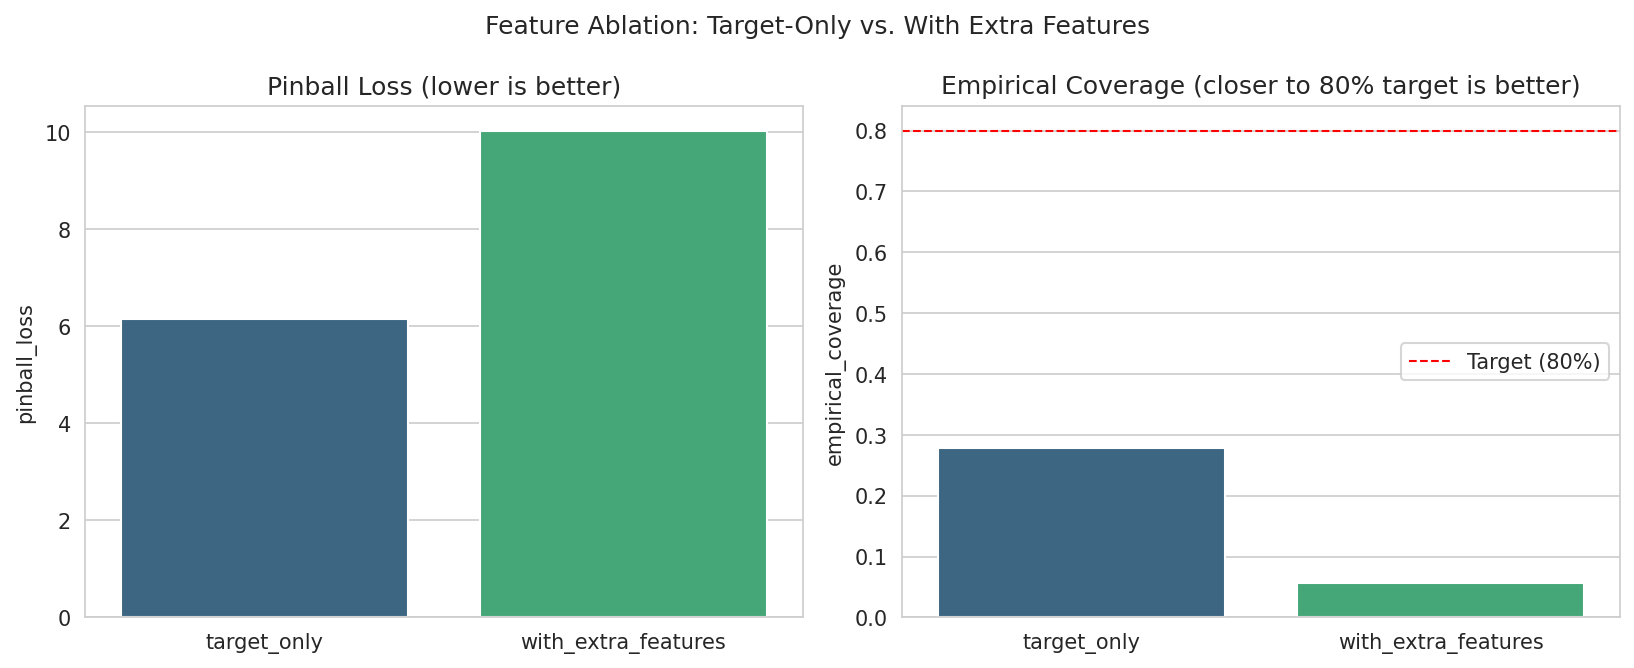

In [3]:
ablation_df = log_df[log_df['run_type'] == 'ablation_study']
display(ablation_df[['tag', 'n_features', 'pinball_loss', 'mae', 'empirical_coverage']])

img_path = Path('../reports/figures/ablation_comparison.png')
if img_path.exists():
    display(Image.open(img_path))
else:
    print('Run `python -m src.experiments.ablation_study` first to generate this chart.')

## 3. Rolling-Origin Cross-Validation Results

,fold,pinball_loss,mae,empirical_coverage
9,1.0,12.9511,26.2309,0.0612
10,2.0,12.4745,25.2445,0.0408
11,3.0,12.2986,25.0663,0.0416


Mean pinball loss across folds: 12.575 (std: 0.338)


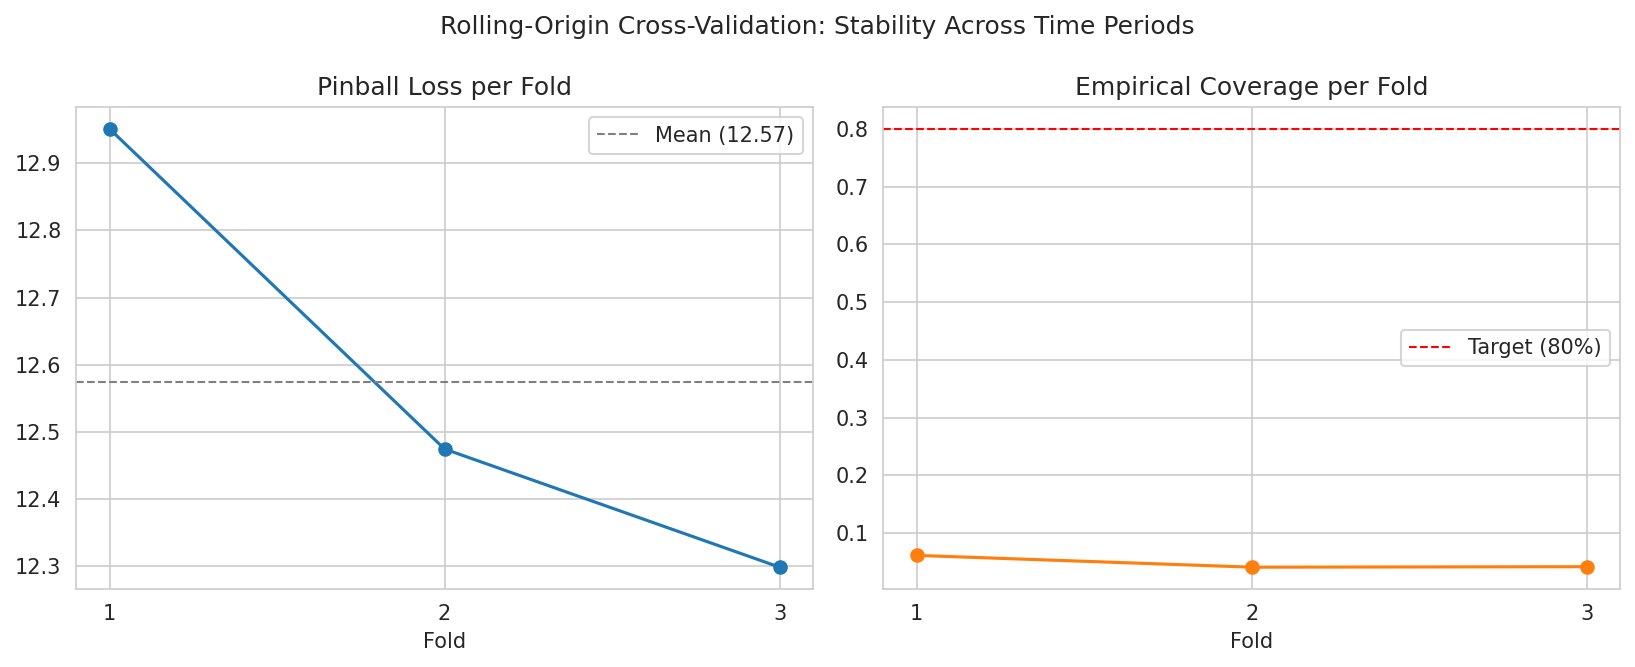

In [4]:
cv_df = log_df[log_df['run_type'] == 'rolling_cv'].sort_values('fold')
display(cv_df[['fold', 'pinball_loss', 'mae', 'empirical_coverage']])
print(f"Mean pinball loss across folds: {cv_df['pinball_loss'].mean():.3f} (std: {cv_df['pinball_loss'].std():.3f})")

img_path = Path('../reports/figures/rolling_cv_folds.png')
if img_path.exists():
    display(Image.open(img_path))
else:
    print('Run `python -m src.experiments.rolling_cv` first to generate this chart.')

## 4. Per-SKU Segment Analysis Results

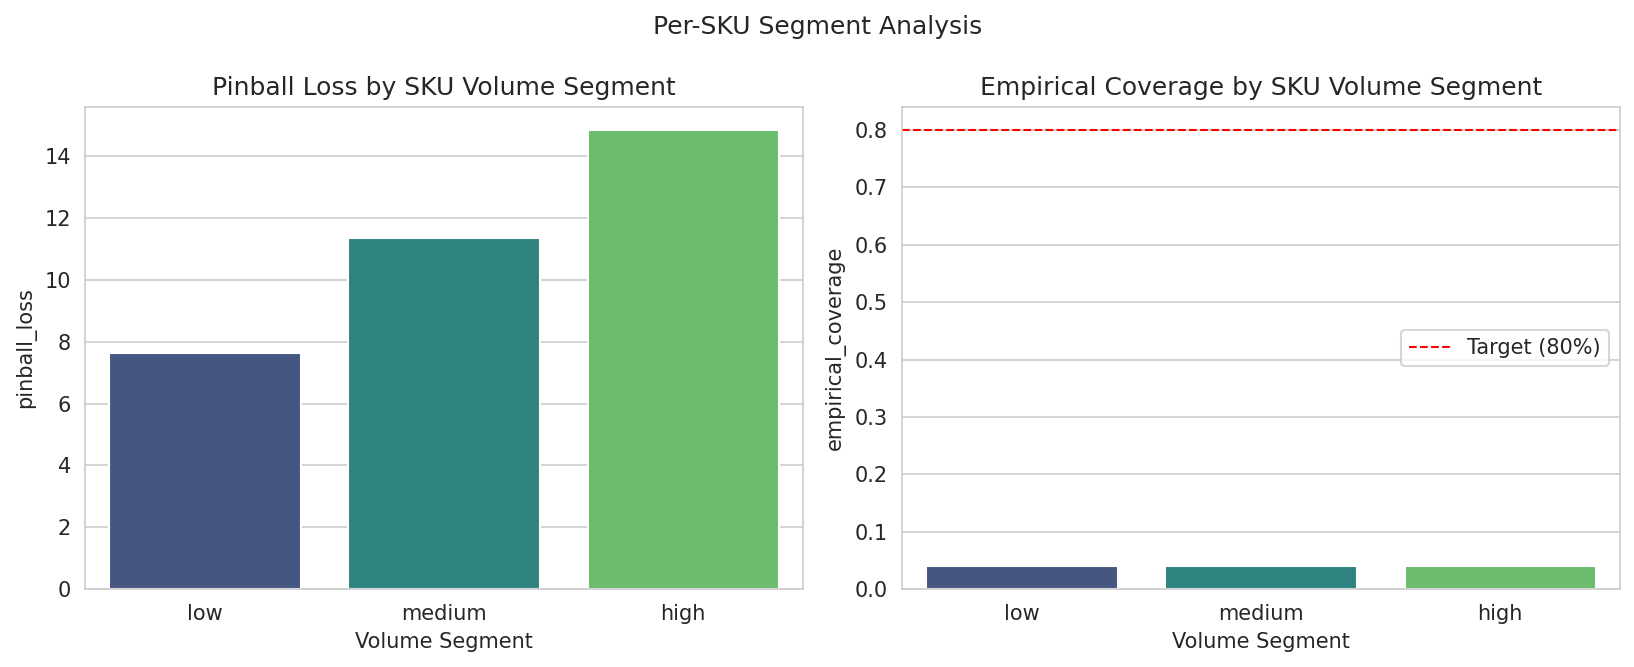

In [5]:
img_path = Path('../reports/figures/segment_analysis_comparison.png')
if img_path.exists():
    display(Image.open(img_path))
else:
    print('Run `python -m src.experiments.segment_analysis` first to generate this chart.')

## 5. Cross-Experiment Overview

One chart ranking every logged run (across ALL experiment types) by pinball
loss -- useful once you've run several experiments and want a single
at-a-glance comparison instead of checking each section above individually.

Saved plot: ../reports/figures/experiment_log_overview.png


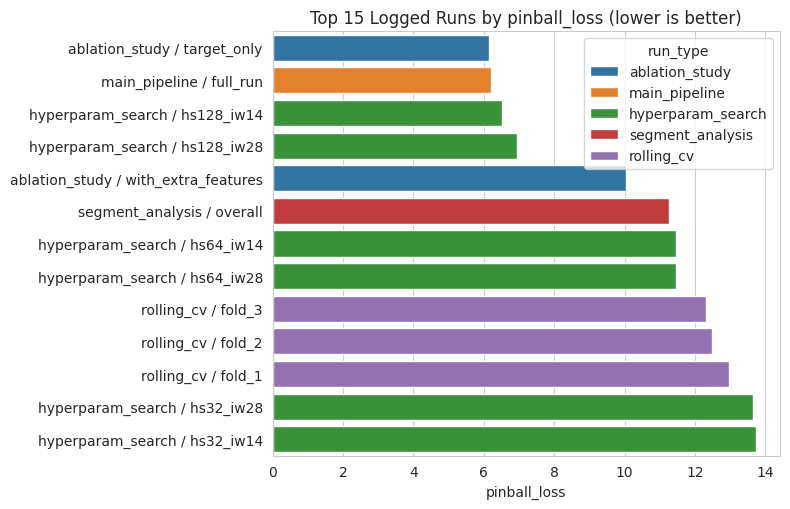

In [6]:
if len(log_df.dropna(subset=['pinball_loss'])) > 0:
    plot_experiment_log_overview(log_df, metric='pinball_loss', top_n=15, save_dir=Path('../reports/figures'))
    plt.show()
else:
    print('No runs with pinball_loss logged yet.')

## Summary

- **Hyperparameters:** check the heatmap above for the best `hidden_size`/`input_window` combination on pinball loss.
- **Ablation:** if `with_extra_features` doesn't clearly beat `target_only`, the extra feature channels may need more epochs, more data, or aren't actually predictive on this dataset -- worth investigating rather than assuming they help.
- **Rolling CV:** a large std across folds means the single train/val/test split result in the main pipeline run may not generalize -- report the CV mean instead when this happens.
- **Segmentation:** if pinball loss is much worse for low-volume SKUs, consider a separate/simpler model for intermittent items rather than one global model for everything.